# Spektrální signatury, pokročilá verze: model PROSAIL, nasycení indexů a odhad LAI

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Spektrální signatury](https://openskylab.space/edu_viz_spectral_signatures.html) · [English version](spectral_signatures_pro_en.ipynb)

Pokročilá verze notebooku ke spektrálním signaturám. Křivky z vizuálu tu počítá skutečný model přenosu záření PROSAIL, který spojuje optiku listu (PROSPECT) s porostem (SAIL). Ukážeš v něm, proč se NDVI nasycuje, sestavíš tabulku simulací a z ní odhadneš LAI pro každý pixel dvou snímků Sentinel-2 u Roztok, včetně nejistoty a míst, kde model selhává.

**Cíl:** zjistit, která pásma nesou informaci o chlorofylu, vodě, sušině a LAI, porovnat nasycení NDVI, NDRE a CIre v modelu, pochopit, proč je inverze modelu nejednoznačná, a odhadnout LAI z inverze tabulkou simulací se znalostí jejích mezí.

**Data:** dva snímky Sentinel-2 L2A dlaždice 33UVR (14. 5. a 21. 7. 2024) z katalogu Earth Search na AWS, výřez 4 × 4 km kolem Roztok a Únětic; třídy ESA WorldCover 2021 v200. Simulace počítá balíček `prosail` (PROSPECT-5 a 4SAIL) přímo v notebooku. Stahuje se asi 40 MB, tabulka simulací trvá 1 až 3 minuty. Pozemní měření LAI k výřezu nejsou k dispozici, takže výsledky inverze jsou odhady modelu, ne ověřené hodnoty.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 75 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava, dva snímky a model

In [1]:
%pip install -q rasterio prosail

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio, prosail
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestNeighbors
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

In [3]:
DATES = ["S2A_33UVR_20240514_0_L2A", "S2B_33UVR_20240721_0_L2A"]   # ◀ parametr: dva snímky jedné sezóny (jaro, léto)
LON, LAT, HALF = 14.375, 50.155, 2000                              # ◀ parametr: střed výřezu a jeho poloviční šířka (m)
scenes = {}
for item_id in DATES:
    refl, scl, wl, grid, item = s2_window(item_id, LON, LAT, HALF)
    day = item["properties"]["datetime"][:10]
    scenes[day] = dict(refl=refl, clear=np.isin(scl, [4, 5, 6]), sza=90 - item["properties"]["view:sun_elevation"])
    print(f"{item_id}: bez mraků {scenes[day]['clear'].mean():.1%} výřezu, zenitový úhel Slunce {scenes[day]['sza']:.1f}°")
DAYS = list(scenes)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}

# pásma pro model a jejich spektrální citlivost, přibližně Gaussovou křivkou podle středu a pološířky z katalogu
INV = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
cwl = np.array([item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in INV]) * 1000
fwhm = np.array([item["assets"][b]["eo:bands"][0]["full_width_half_max"] for b in INV]) * 1000
WL = np.arange(400, 2501)
SRF = np.exp(-0.5 * ((WL[None] - cwl[:, None]) / (fwhm[:, None] / 2.355)) ** 2)
SRF /= SRF.sum(1, keepdims=True)

def prosail_s2(cab=40, cw=0.012, cm=0.008, lai=3, ala=57, n=1.5, psoil=0.5, rsoil=1.0, sza=32, full=False):
    """Odrazivost porostu z PROSAIL (PROSPECT-5 + 4SAIL): celé spektrum 400–2500 nm (full=True), nebo pásma Sentinelu-2.
    cab chlorofyl (µg/cm²), cw voda v listu (cm), cm sušina (g/cm²), lai index listové plochy, ala průměrný úhel listů (°),
    n struktura listu, psoil podíl suché půdy, rsoil jas půdy; karotenoidy = cab/4, pohled kolmo dolů."""
    r = prosail.run_prosail(n, cab, cab / 4, 0.0, cw, cm, lai=lai, lidfa=ala, hspot=0.01, tts=sza, tto=0.0, psi=0.0,
                            typelidf=2, rsoil=rsoil, psoil=psoil, factor="SDR")
    return r if full else SRF @ r

S2A_33UVR_20240514_0_L2A: bez mraků 99.2% výřezu, zenitový úhel Slunce 32.9°


S2B_33UVR_20240721_0_L2A: bez mraků 98.8% výřezu, zenitový úhel Slunce 31.5°


## 2. Co model umí

PROSAIL počítá odrazivost porostu z vlastností listů (chlorofyl `cab`, voda `cw`, sušina `cm`, struktura `n`) a porostu (index listové plochy `lai`, průměrný úhel listů `ala`, půda pod porostem). Spektrum v krocích 1 nm převedeme na pásma Sentinelu-2. Spektrální citlivost pásem tu nahrazujeme Gaussovou křivkou, což je přiblížení; přesné křivky zveřejňuje ESA.

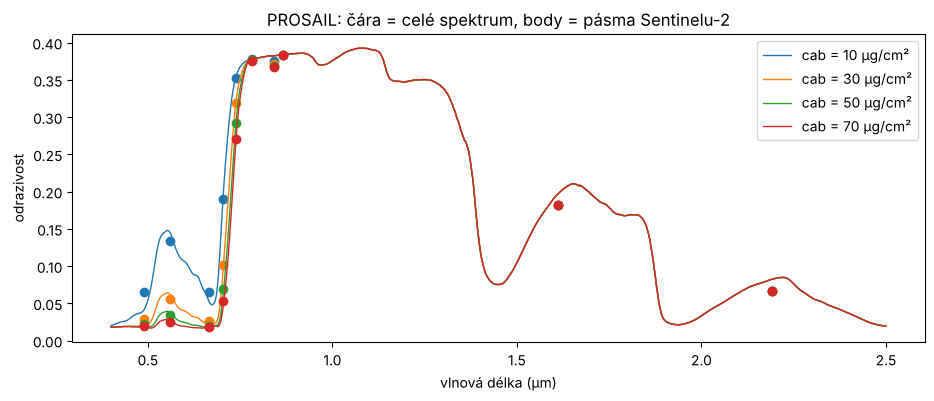

,blue,green,red,rededge1,rededge2,rededge3,nir,nir08,swir16,swir22
cab 20→60,-0.018,-0.051,-0.016,-0.072,-0.054,-0.001,-0.005,-0.000,0.000,0.000
cw 0.005→0.03,-0.000,-0.000,-0.000,-0.000,-0.002,-0.003,-0.006,-0.005,-0.131,-0.067
cm 0.004→0.012,-0.000,-0.001,-0.000,-0.005,-0.051,-0.078,-0.076,-0.080,-0.041,-0.025
lai 1→5,-0.037,-0.038,-0.054,-0.042,0.088,0.153,0.134,0.141,-0.076,-0.095
ala 40→70,-0.002,-0.009,0.005,-0.024,-0.122,-0.147,-0.139,-0.142,-0.045,-0.000


In [4]:
VAR, VALUES = "cab", [10, 30, 50, 70]      # ◀ parametr: proměnná (cab, cw, cm, lai, ala) a její hodnoty
UNITS = {"cab": "µg/cm²", "cw": "cm", "cm": "g/cm²", "lai": "m²/m²", "ala": "°"}
fig, ax = plt.subplots(figsize=(11, 4))
for v in VALUES:
    r = prosail_s2(**{VAR: v}, full=True)
    line, = ax.plot(WL / 1000, r, lw=1, label=f"{VAR} = {v} {UNITS[VAR]}")
    ax.plot(cwl / 1000, SRF @ r, "o", color=line.get_color())
ax.set(xlabel="vlnová délka (µm)", ylabel="odrazivost", title="PROSAIL: čára = celé spektrum, body = pásma Sentinelu-2"); ax.legend(); plt.show()

# citlivost: změna odrazivosti v pásmu, když proměnná přejde z nižší na vyšší hodnotu (ostatní výchozí)
STEPS = {"cab": (20, 60), "cw": (0.005, 0.03), "cm": (0.004, 0.012), "lai": (1, 5), "ala": (40, 70)}
sens = pd.DataFrame({k: prosail_s2(**{k: hi}) - prosail_s2(**{k: lo}) for k, (lo, hi) in STEPS.items()}, index=INV).T
sens.index = [f"{k} {lo}→{hi}" for k, (lo, hi) in STEPS.items()]
sens.round(3)

> **✏️ Úkol 1.** Spusť buňku pro `cab`, `cw`, `cm`, `lai` a `ala`. Podle grafů a tabulky citlivosti řekni, která pásma Sentinelu-2 nesou informaci o chlorofylu, o vodě v listech a o LAI. Které dvě proměnné mění red edge a NIR skoro stejně, jen s opačným znaménkem, a co to znamená pro odhad LAI z jednoho snímku?

*Tvoje odpověď:* 

## 3. Nasycení indexů v modelu

Necháme LAI růst od 0 do 7 pro tři obsahy chlorofylu a sledujeme NDVI, NDRE a CIre = NIR/RE1 − 1 (Gitelson a kol. 2005). Tabulka ukazuje, při jakém LAI index dosáhne 90 % rozdílu mezi holou půdou a LAI 7, a jak moc index posune změna chlorofylu, vztaženo k tomuto rozdílu.

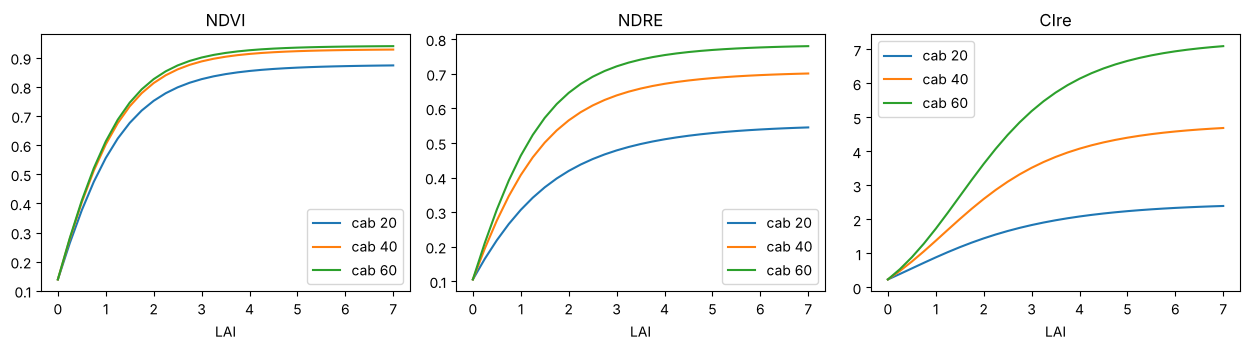

,LAI na 90 % (cab 20),LAI na 90 % (cab 40),LAI na 90 % (cab 60),vliv cab 20–60 při LAI 3
NDVI,2.75,2.50,2.5,0.09
NDRE,3.75,3.25,3.0,0.41
CIre,4.75,4.50,4.5,0.75


In [5]:
INDICES = {                                                            # ◀ parametr: indexy; přidej vlastní, např. MTCI
    "NDVI": lambda b: (b["nir"] - b["red"]) / (b["nir"] + b["red"]),
    "NDRE": lambda b: (b["nir"] - b["rededge1"]) / (b["nir"] + b["rededge1"]),
    "CIre": lambda b: b["nir"] / b["rededge1"] - 1,
}
LAIS = np.arange(0, 7.01, 0.25)
CABS = [20, 40, 60]
sim = {cab: [dict(zip(INV, prosail_s2(cab=cab, lai=l))) for l in LAIS] for cab in CABS}
fig, ax = plt.subplots(1, len(INDICES), figsize=(4.2 * len(INDICES), 3.6))
rows = {}
for a, (name, f) in zip(ax, INDICES.items()):
    curves = {cab: np.array([f(b) for b in sim[cab]]) for cab in CABS}
    for cab, v in curves.items():
        a.plot(LAIS, v, label=f"cab {cab}")
        rel = (v - v[0]) / (v[-1] - v[0])                            # 0 = holá půda, 1 = LAI 7
        rows.setdefault(name, {})[f"LAI na 90 % (cab {cab})"] = LAIS[np.argmax(rel >= 0.9)]
    i3, v40 = list(LAIS).index(3.0), curves[40]
    rows[name]["vliv cab 20–60 při LAI 3"] = (curves[60][i3] - curves[20][i3]) / (v40[-1] - v40[0])
    a.set(xlabel="LAI", title=name); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Úkol 2.** Při jakém LAI se nasytí NDVI a při jakém NDRE a CIre? Proč se indexy s červenou hranou nasycují později? Jakou cenu za to platí (poslední sloupec)? Přidej do `INDICES` vlastní index, např. MTCI = (B6 − B5)/(B5 − B4), tj. `(b["rededge2"] - b["rededge1"]) / (b["rededge1"] - b["red"])`, a zařaď ho mezi ostatní.

*Tvoje odpověď:* 

## 4. Tabulka simulací a jeden pixel

Model neumí počítat pozpátku. Proto spustíme tisíce simulací s náhodnými hodnotami proměnných v zadaných rozsazích a pro pixel hledáme ty, jejichž pásma se nejvíc podobají naměřeným (nejmenší RMSE). Rozsahy jsou apriorní znalost: co o porostu víme předem. Pro každý snímek se tabulka počítá s jeho výškou Slunce.

In [6]:
N_LUT = 20000                                                          # ◀ parametr: počet simulací v tabulce
RANGES = {"n": (1.2, 2.2), "cab": (10, 80), "cw": (0.002, 0.04), "cm": (0.002, 0.015),
          "lai": (0, 7), "ala": (30, 80), "psoil": (0, 1), "rsoil": (0.5, 1.5)}   # ◀ parametr: rozsahy proměnných (apriorní znalost)
rng = np.random.default_rng(0)
lut = pd.DataFrame({k: rng.uniform(lo, hi, N_LUT) for k, (lo, hi) in RANGES.items()})
t0 = time.time()
LUT = {day: np.array([prosail_s2(sza=s["sza"], **p) for p in lut.to_dict("records")]) for day, s in scenes.items()}
print(f"{N_LUT} simulací pro {len(DAYS)} snímky za {time.time() - t0:.0f} s")

20000 simulací pro 2 snímky za 58 s


2024-05-14, bod 14.3516, 50.1632: NDVI 0.83, nejlepší shoda RMSE 0.0082


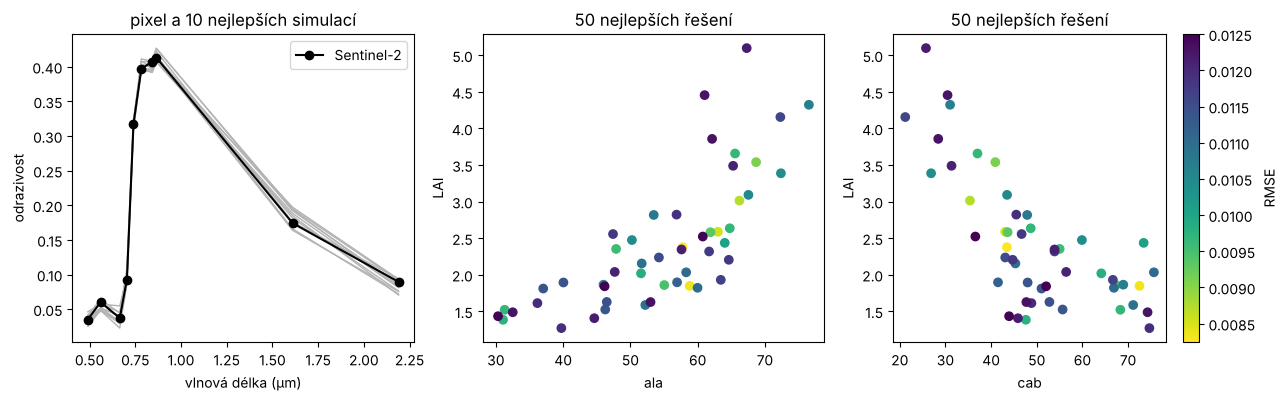

,5%,50%,95%,variační koeficient
lai,1.417,2.219,4.248,0.370
cab,27.553,47.805,73.878,0.285
ccc,71.138,111.995,146.626,0.220
ala,31.842,56.894,70.665,0.213
cw,0.012,0.025,0.037,0.351


In [7]:
K = 50                                     # ◀ parametr: kolik nejlepších řešení z tabulky vzít
PLON, PLAT = 14.3516, 50.1632              # ◀ parametr: bod (pole u Únětic); zkus les 14.366, 50.148
day = DAYS[0]
x, y = Transformer.from_crs(4326, grid[1], always_xy=True).transform(PLON, PLAT)
col, row = [int(v) for v in ~grid[0] * (x, y)]
obs = np.array([scenes[day]["refl"][b][row, col] for b in INV])
rmse = np.sqrt(((LUT[day] - obs) ** 2).mean(1))
best = np.argsort(rmse)[:K]
sol = lut.iloc[best].assign(ccc=lambda d: d.lai * d.cab, rmse=rmse[best])
print(f"{day}, bod {PLON}, {PLAT}: NDVI {(obs[6] - obs[2]) / (obs[6] + obs[2]):.2f}, nejlepší shoda RMSE {rmse[best[0]]:.4f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in best[:10]:
    ax[0].plot(cwl / 1000, LUT[day][i], color="0.7", lw=1)
ax[0].plot(cwl / 1000, obs, "ko-", label="Sentinel-2"); ax[0].set(xlabel="vlnová délka (µm)", ylabel="odrazivost", title="pixel a 10 nejlepších simulací"); ax[0].legend()
for a, v in zip(ax[1:], ["ala", "cab"]):
    s = a.scatter(sol[v], sol.lai, c=sol.rmse, cmap="viridis_r"); a.set(xlabel=v, ylabel="LAI", title=f"{K} nejlepších řešení")
fig.colorbar(s, ax=ax[2], label="RMSE"); plt.show()
summary = sol[["lai", "cab", "ccc", "ala", "cw"]].describe(percentiles=[0.05, 0.5, 0.95]).T[["5%", "50%", "95%"]]
summary["variační koeficient"] = sol[["lai", "cab", "ccc", "ala", "cw"]].std() / sol[["lai", "cab", "ccc", "ala", "cw"]].mean()
summary.round(3)

> **✏️ Úkol 3.** Jak široké je rozpětí LAI mezi nejlepšími řešeními a jak souvisí s úhlem listů a chlorofylem (grafy vpravo)? Porovnej variační koeficient `lai`, `cab` a jejich součinu `ccc` (chlorofyl v porostu, µg na cm² půdy). Proč je součin určen lépe než každá složka zvlášť? Zkus `K = 10` a `K = 200` a bod v lese.

*Tvoje odpověď:* 

## 5. Mapa LAI a kde model nesedí

Stejný postup pro všechny pixely výřezu. Pro každý pixel dostaneme medián LAI z nejlepších řešení, jejich směrodatnou odchylku jako míru nejistoty a RMSE nejlepší simulace jako míru, jak dobře model pixel vůbec vysvětlí.

inverze 160000 pixelů × 2 snímky za 13 s


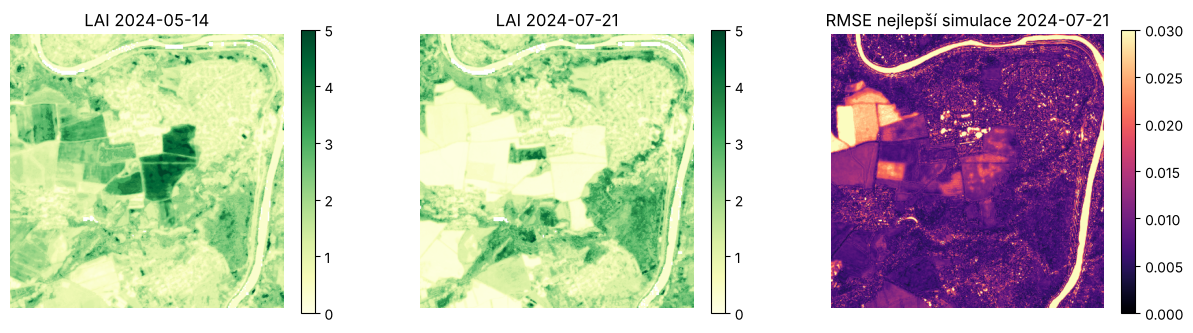

2024-05-14               2024-07-21              
                lai lai_sd   rmse        lai lai_sd   rmse
les           1.630  0.809  0.008      2.077  0.940  0.007
louka         1.148  0.516  0.009      1.236  0.621  0.008
pole          1.947  0.782  0.008      0.228  0.175  0.011
zástavba      0.712  0.352  0.010      0.791  0.389  0.010
voda          0.346  0.545  0.034      0.346  0.545  0.039

In [8]:
def invert(day, k=K):
    """Pro každý pixel najde k simulací nejbližších v odrazivosti (nejmenší RMSE) a vrátí medián LAI, jeho rozptyl, obsah chlorofylu v porostu a RMSE."""
    X = np.dstack([scenes[day]["refl"][b] for b in INV]).reshape(-1, len(INV))
    d, idx = NearestNeighbors(n_neighbors=k).fit(LUT[day]).kneighbors(X)
    lai, cab = lut.lai.values[idx], lut.cab.values[idx]
    sh = wc.shape
    return dict(lai=np.median(lai, 1).reshape(sh), lai_sd=lai.std(1).reshape(sh),
                ccc=np.median(lai * cab, 1).reshape(sh), rmse=(d[:, 0] / np.sqrt(len(INV))).reshape(sh))

t0 = time.time()
inv = {day: invert(day) for day in DAYS}
print(f"inverze {wc.size} pixelů × {len(DAYS)} snímky za {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, day in zip(ax, DAYS):
    im = a.imshow(np.where(scenes[day]["clear"], inv[day]["lai"], np.nan), cmap="YlGn", vmin=0, vmax=5); a.set_title(f"LAI {day}"); fig.colorbar(im, ax=a, shrink=0.8)
im = ax[2].imshow(inv[DAYS[-1]]["rmse"], cmap="magma", vmin=0, vmax=0.03); ax[2].set_title(f"RMSE nejlepší simulace {DAYS[-1]}"); fig.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax: a.axis("off")
plt.show()
tab = pd.DataFrame({(day, q): {name: np.median(inv[day][q][scenes[day]["clear"] & (wc == code)]) for code, name in CLASSES.items()}
                    for day in DAYS for q in ["lai", "lai_sd", "rmse"]})
tab.round(3)

> **✏️ Úkol 4.** Kde je RMSE největší a proč? Proč u vody vyjde nějaké LAI, i když tam žádné listy nejsou, a proč zástavba sedí skoro stejně dobře jako louka? Les tu vychází s LAI kolem 2, zatímco souhrn pozemních měření (Asner a kol. 2003) uvádí pro stálezelené lesy mírného pásu průměr 5,1 až 6,7. Které předpoklady PROSAILu (jedna souvislá vrstva listů, žádné kmeny, mezery ani stíny korun) k rozdílu přispívají?

*Tvoje odpověď:* 

## 6. LAI, NDVI a nejistota na skutečných datech

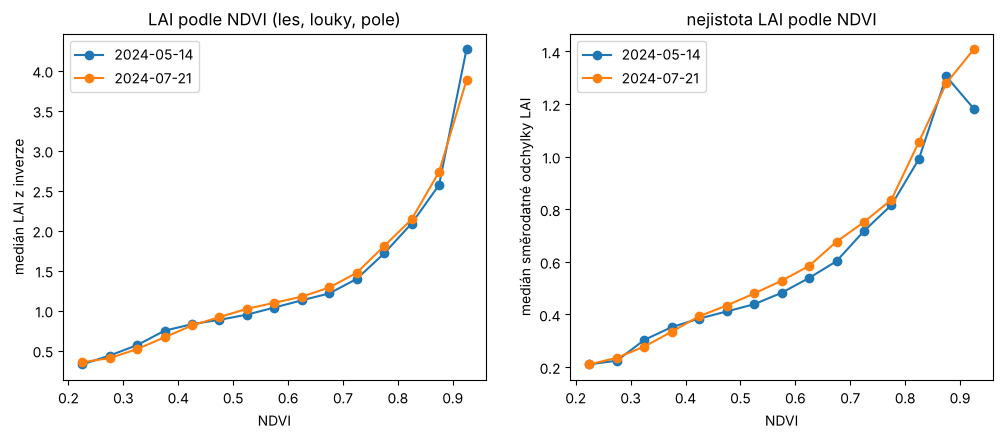

,NDVI 2024-05-14,NDVI 2024-07-21,LAI 2024-05-14,LAI 2024-07-21
les,0.77,0.82,1.63,2.08
louka,0.66,0.67,1.15,1.24
pole,0.76,0.19,1.95,0.23


In [9]:
veg = np.isin(wc, [10, 30, 40])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for day in DAYS:
    r = scenes[day]["refl"]; m = veg & scenes[day]["clear"]
    ndvi = ((r["nir"] - r["red"]) / (r["nir"] + r["red"]))[m]
    lai, sd = inv[day]["lai"][m], inv[day]["lai_sd"][m]
    bins = np.arange(0.2, 0.96, 0.05); k = np.digitize(ndvi, bins)
    mid = [(bins[i - 1] + bins[i]) / 2 for i in range(1, len(bins)) if (k == i).sum() > 50]
    ax[0].plot(mid, [np.median(lai[k == i]) for i in range(1, len(bins)) if (k == i).sum() > 50], "o-", label=day)
    ax[1].plot(mid, [np.median(sd[k == i]) for i in range(1, len(bins)) if (k == i).sum() > 50], "o-", label=day)
ax[0].set(xlabel="NDVI", ylabel="medián LAI z inverze", title="LAI podle NDVI (les, louky, pole)"); ax[0].legend()
ax[1].set(xlabel="NDVI", ylabel="medián směrodatné odchylky LAI", title="nejistota LAI podle NDVI"); ax[1].legend()
plt.show()
r0, r1 = scenes[DAYS[0]]["refl"], scenes[DAYS[1]]["refl"]
ndvi0, ndvi1 = [(r["nir"] - r["red"]) / (r["nir"] + r["red"]) for r in (r0, r1)]
both = scenes[DAYS[0]]["clear"] & scenes[DAYS[1]]["clear"]
pd.DataFrame({name: {"NDVI " + DAYS[0]: np.median(ndvi0[both & (wc == c)]), "NDVI " + DAYS[1]: np.median(ndvi1[both & (wc == c)]),
                     "LAI " + DAYS[0]: np.median(inv[DAYS[0]]["lai"][both & (wc == c)]), "LAI " + DAYS[1]: np.median(inv[DAYS[1]]["lai"][both & (wc == c)])}
              for c, name in CLASSES.items() if c in (10, 30, 40)}).T.round(2)

> **✏️ Úkol 5.** Od jakého NDVI roste nejistota LAI nejrychleji a jak to souvisí s nasycením z kroku 3? Jak se mezi květnem a červencem změnilo NDVI a LAI na polích, loukách a v lese? Proč by samotné NDVI podcenilo rozdíl mezi dvěma hustými porosty?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Zužte rozsahy v `RANGES` podle toho, co o porostu víš (např. `ala` 50–65, `cab` 30–60), a spusť kroky 4 až 6 znovu. Jak se změní nejistota LAI? Co se stane, když apriorní znalost neplatí, třeba pro les s jiným úhlem listů?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); registr AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje.
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Jacquemoud, S. a kol. (2009). PROSPECT + SAIL models: A review of use for vegetation characterization. *Remote Sensing of Environment* 113, S56–S66. https://doi.org/10.1016/j.rse.2008.01.026
- Feret, J.-B. a kol. (2008). PROSPECT-4 and 5: Advances in the leaf optical properties model separating photosynthetic pigments. *Remote Sensing of Environment* 112, 3030–3043. https://doi.org/10.1016/j.rse.2008.02.012
- Verhoef, W., Jia, L., Xiao, Q., Su, Z. (2007). Unified optical-thermal four-stream radiative transfer theory for homogeneous vegetation canopies. *IEEE Transactions on Geoscience and Remote Sensing* 45, 1808–1822. https://doi.org/10.1109/TGRS.2007.895844
- Gómez-Dans, J. *prosail*: Python bindings for PROSPECT and SAIL. https://github.com/jgomezdans/prosail
- Combal, B. a kol. (2002). Retrieval of canopy biophysical variables from bidirectional reflectance using prior information to solve the ill-posed inverse problem. *Remote Sensing of Environment* 84, 1–15.
- Gitelson, A. A. a kol. (2005). Remote estimation of canopy chlorophyll content in crops. *Geophysical Research Letters* 32, L08403. https://doi.org/10.1029/2005GL022688
- Asner, G. P., Scurlock, J. M. O., Hicke, J. A. (2003). Global synthesis of leaf area index observations: implications for ecological and remote sensing studies. *Global Ecology and Biogeography* 12, 191–205. https://doi.org/10.1046/j.1466-822X.2003.00026.x
- Pedregosa, F. a kol. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### Jak citovat

OpenSkyLab (2026). Spektrální signatury, pokročilá verze: model PROSAIL, nasycení indexů a odhad LAI [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*